# OSEMN Exercises

In [40]:
#NOTE
# separatore.join(lista_elementi) serve ad unire gli elementi di una lista, separandoli con il carattere separatore. 
#esempio: "-".join(["A","B"]     ->     stampa a schermo: A-B.    Se non metto nulla, unisce gli elementi e basta.
#quindi join NON elimina spazi bianchi! se nella lista cè un carattere che è unno spazio bianco, questo viene comunque trattato come carattere!

In [41]:
%matplotlib inline   
import pandas as pd  
import numpy as np

In [42]:
# 1) first row: to show graphs (matplotlib) on jupiter just below the code
# 2) pandas: to manipulate tabular data (tabelle, excel...)

1\. Create a random list of number and then save it to a text file named "simple_data.txt"

In [43]:
import numpy as np


random_numbers = np.random.randint(1, 101, size=10)  #10 numeri da 1 a 100
np.savetxt("simple_data.txt", random_numbers, fmt='%d')
#fmt='%d' serve per formattarli come numeri interi. Altrimenti, np.savetxt li converte in float 
# ad esempio 35 diventa 3.500000000*10^1
print(random_numbers)

[ 49 100  31  46  47  73  68  82  22  16]


2\. Create a random matrix of 5x5 and then save it to a text file named "data.txt"

In [44]:
import numpy as np


random_matrix = np.random.randint(1, 101, size=(5, 5))
#matrice 5x5 di numeri interi casuali (ad esempio tra 1 e 100)
np.savetxt("data.txt", random_matrix, fmt='%d')
# fmt='%d' serve per formattare i numeri come interi
print(random_matrix)

[[97 95  3 36 15]
 [76 45 78 73 67]
 [46 22 40 20 47]
 [80 83 67 60 29]
 [17  4 64 42 88]]


3\. Load the saved txt file of point 2 and convert it to a csv file (by hand)

In [45]:

# Apriamo il file di testo in lettura ("r"=read) e il nuovo file CSV in scrittura ("w"=write)
with open("data.txt", "r") as txt_file, open("data.csv", "w") as csv_file:
    for line in txt_file:
        # strip() rimuove gli spazi vuoti superflui e il carattere invisibile \n che fa andare a capo
        # split() trasforma la stringa della riga in una lista di numeri
        elements = line.strip().split()
        
        # Uniamo gli elementi della lista in una singola stringa, MA usando la virgola come separatore
        csv_line = ",".join(elements)
        
        # Scriviamo la riga formattata nel file CSV aggiungendo l'andata a capo (\n)
        csv_file.write(csv_line + "\n")

#lettura del file senza intestazione (altrimenti la prima riga è presa come intestazione di default)
lettura = pd.read_csv("data.csv", header=None)
print(lettura)
#RICORDO: gli indici di riga e colonna non compaiono nel file: se apro come file di testo non li vedo

    0   1   2   3   4
0  97  95   3  36  15
1  76  45  78  73  67
2  46  22  40  20  47
3  80  83  67  60  29
4  17   4  64  42  88


4\. load the binary file named *credit_card.dat* and convert the data into the real credit-card number. 
Ogni riga nel file è una sequenza di bit. Alla fine della riga è presente il carattere \n (da rimuovere) mentre prima di questo vi sono 4 bit di riempiment, anch'essi da rimuovere.
L'ultima riga è solo riempimento.
Ogni 6 bit è presente un carattere, compresi gli spazi ogni 4 cifre di carta di credito (codificati da 100000)

**hint**: use the `chr()` function to convert a number to a char

In [46]:
with open("credit_card.dat", "r") as file:
    for j,line in enumerate(file,1):   #parte a indicizzare le linee da 1
        char_list = []
        sequenza = line.rstrip()[:-4]  #tolgo il carattere \n a destra (r davanti a strip). Tolgo gli ultimi 4 bit di padding
        if len(sequenza)%6==0 and len(sequenza) != 0:
            for i in range(0,len(sequenza),6):
                chunk = sequenza[i : i + 6]
                char_list.append(chr(int(chunk,2)))
            cc_number="".join(char_list)   #unisce tutti gli elementi della lista per formare la j_esima carta di credito
            print("carta ",j,":",cc_number)

carta  1 : 7648 5673 3775 2271
carta  2 : 3257 8247 3354 2266
carta  3 : 2722 0001 4011 6652
carta  4 : 0661 3063 3742 3150
carta  5 : 0432 1608 1462 4742
carta  6 : 5827 2027 8785 7303
carta  7 : 5774 8528 2087 1117
carta  8 : 8140 1210 6352 2845
carta  9 : 5764 1133 7301 7100
carta  10 : 6456 1737 4126 6726
carta  11 : 1228 8631 7382 0000
carta  12 : 7051 0160 5374 3166
carta  13 : 0618 3587 1630 6376
carta  14 : 1545 5454 7444 5636
carta  15 : 6735 3116 3202 6834
carta  16 : 7287 5011 1547 8413
carta  17 : 7033 2607 3328 4200
carta  18 : 2568 5244 1874 5024
carta  19 : 1684 2253 7570 7118
carta  20 : 0672 2576 0575 6631
carta  21 : 6332 8353 8787 1340
carta  22 : 1813 3361 1175 4211
carta  23 : 2477 6450 8840 2368
carta  24 : 5512 3505 2563 1326
carta  25 : 3083 7882 0621 0025
carta  26 : 4521 5148 8045 0334
carta  27 : 7563 3654 8713 5787
carta  28 : 8324 2664 0476 5561
carta  29 : 0565 2504 7168 3510
carta  30 : 5107 5507 1767 0738
carta  31 : 2462 1821 2448 1443
carta  32 : 2788 

In [47]:
#il secondo for si può fare in un'unica riga: bit_string = "".join(format(byte, "08b") for byte in line)

5\. Load the file "user_data.json", filter the data by the "CreditCardType" field equals to "American Express". Than save the data a to CSV.

In [48]:
%%file esempio_elia.json
{
  "status": "success",
  "total_users": 4,
  "users": [
    {
      "id": 1,
      "name": "Mario Rossi",
      "CreditCardType": "American Express"
    },
    {
      "id": 2,
      "name": "Luigi Bianchi",
      "CreditCardType": "Visa"
    }
  ]
}


Writing esempio_elia.json


In [49]:
#data frame: è una sorta di tabella che consente di effettuare operazioni matematiche in modo veloce tra intere colonne senza cicli for
    #è formato da righe (semplici record) e colonne (le variabili, categorie).

In [51]:
import pandas as pd

# 1. Carichiamo il file JSON in un DataFrame  (lo trasforma in una tabella)
df = pd.read_json("user_data.json")

# 2. Filtriamo i dati dove la colonna "CreditCardType" è "American Express con il primo df[...condizione booleana...]", 
    # mentre df["credit"]==...] è la condizione booleana che, se vera, viene filtrata.
filtered_df = df[df["CreditCardType"] == "American Express"]

# 3. Salviamo il risultato in un file CSV (index=False evita di salvare l'indice numerico del DataFrame)
    # encoding serve a codificare in modo standard i caratteri speciali e le emoiji usando lo standard web utf-8
filtered_df.to_csv("american_express_users.csv", index=False, encoding="utf-8")   

6\. Load the file from this url: [https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1](https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1) with Pandas. 
+ Explore the data (see the info of the data)
+ Draw the istogram of the 'class' field. Decribe wath yuou see


<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   int64
 1   cap-shape                 8124 non-null   int64
 2   cap-surface               8124 non-null   int64
 3   cap-color                 8124 non-null   int64
 4   bruises                   8124 non-null   int64
 5   odor                      8124 non-null   int64
 6   gill-attachment           8124 non-null   int64
 7   gill-spacing              8124 non-null   int64
 8   gill-size                 8124 non-null   int64
 9   gill-color                8124 non-null   int64
 10  stalk-shape               8124 non-null   int64
 11  stalk-root                8124 non-null   int64
 12  stalk-surface-above-ring  8124 non-null   int64
 13  stalk-surface-below-ring  8124 non-null   int64
 14  stalk-color-above-ring    8124 non-null   int64
 15

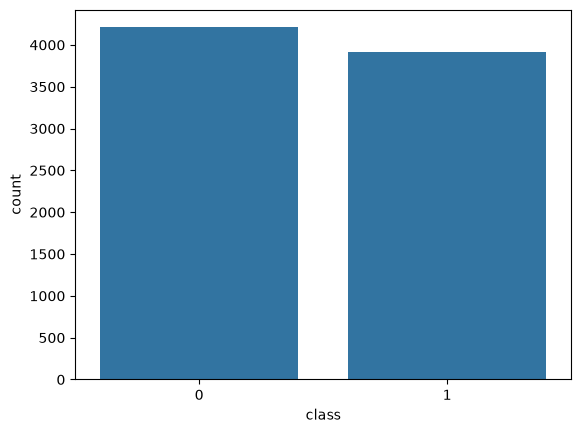

In [52]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Carica il dataset
url = "https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1"
df = pd.read_csv(url)

# 2. Esplora i dati
df.info()

# 3. Disegna l'istogramma (countplot)
sns.countplot(data=df, x='class')
plt.show()

7\. Load the remote file [https://www.dropbox.com/s/vkl89yce7xjdq4n/regression_generated.csv?dl=1](https://www.dropbox.com/s/vkl89yce7xjdq4n/regression_generated.csv?dl=1) with Pandas and plot a scatter plot all possible combination of the following fields:
    
  + features_1
  + features_2
  + features_3

In [53]:
#scatter plot = grafico a dispersione. Serve a capire se c'e una correlazoine tra due variabili, X e Y, disposte sui 2 assi.

#sns.pairplot() crea una griglia (matrice) di grafici che mostra tutte le combinazioni possibili 
    #a due a due tra le colonne selezionate (features_1, features_2, features_3)
    #!!!  sulla diagonale non può comparire il grafico a dispersione, perciò seaborn stampa una distribuzione della variabile in questione,
        #per osservare come sono distribuiti i dati.


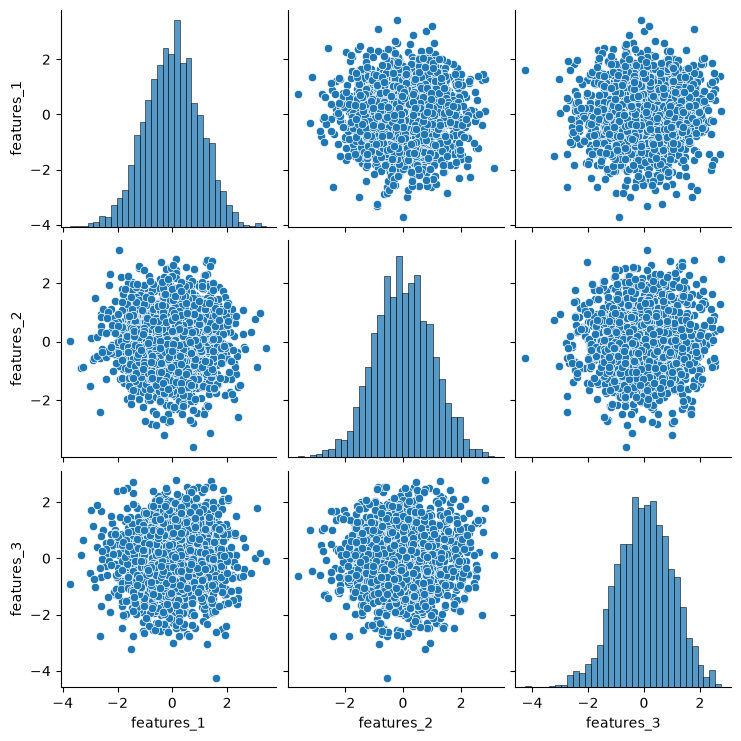

In [54]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Carica il dataset
url = "https://www.dropbox.com/s/vkl89yce7xjdq4n/regression_generated.csv?dl=1"
df = pd.read_csv(url)

# 2. Seleziona le colonne richieste
cols = ['features_1', 'features_2', 'features_3']

# 3. Disegna tutte le combinazioni di scatter plot
sns.pairplot(df[cols])
plt.show()

8\. Load the same file of point 6, and convert the file to json with Pandas.

In [55]:
import pandas as pd

# 1. Carica il dataset
url = "https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1"
df = pd.read_csv(url)

# 2. Converti e salva il DataFrame in un file JSON
df.to_json('mushrooms.json', orient='records', indent=4)

In [56]:
#orient='records': È il formato più comune per i dataset tabulari; trasforma il file in una lista di dizionari 
    #(dove ogni riga è un oggetto JSON che può essere aperto e contiene una lista)

#indent=4: Serve solo a formattare il file JSON in modo "leggibile" (indentato) per gli esseri umani.